# Ramsey-vs-Q-axis analysis (v2: global-optimizer fit)

Same workflow as `analyze_ramsey_qaxis_scan.ipynb`, but the per-B-field Ramsey
fit uses a **global optimizer** instead of plain LSQ:

1. `scipy.optimize.differential_evolution` finds the global best-fit (escapes
   the local/sub-harmonic minima that plain curve_fit fell into).
2. `scipy.optimize.curve_fit`, seeded at that global solution, returns the
   Gauss-Newton covariance `pcov` -> trustworthy parameter errors
   (`sqrt(diag(pcov))`), unlike the L-BFGS-B `hess_inv` errors.

Errors are symmetric/asymptotic: well-constrained params get tight bars, and a
parameter the data can't pin down (e.g. T2* longer than the scan) honestly
returns a large/inf error rather than a falsely-precise one.

In [1]:
import sys, os
sys.path.insert(0, r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository")
import numpy as np
import matplotlib.pyplot as plt
import h5py, glob, datetime
from pathlib import Path
from scipy.optimize import differential_evolution, curve_fit
from analysis.data_loader import load_h5, find_runs, RESULTS_DIR

%matplotlib inline
%load_ext autoreload
%autoreload 2
plt.rcParams["figure.dpi"] = 120

def _scalar(v, default=0.0):
    if v is None: return float(default)
    if isinstance(v, (bytes, bytearray)):
        try: return float(v.decode())
        except Exception: return float(default)
    arr = np.asarray(v)
    if arr.ndim == 0: return float(arr)
    if arr.size == 0: return float(default)
    return float(arr.flat[-1])

def _txt(v, default="?"):
    if isinstance(v, (bytes, bytearray)): return v.decode()
    return default if v is None else str(v)

# Ramsey model: A*cos(2*pi*f*x + phi)*exp(-(|x/tau|)^n) + y0
# x in ms, f in kHz, tau = T2* in ms. Params: [A, f, phi, tau, y0, n]. n is FREE.
def ramsey_model(x, A, f, phi, tau, y0, n):
    return A * np.cos(2 * np.pi * f * x + phi) * np.exp(-(np.abs(x / tau)) ** n) + y0

PARAM_NAMES = ["A", "f", "phi", "tau", "y0", "n"]

def _periodogram_f0(x, y, e):
    """Robust fringe-frequency seed via a weighted floating-mean periodogram.
    At each trial f the model a*cos+b*sin+c is linear, so its residual is
    closed-form. Band = [~0.2/span, within-segment Nyquist], so super-Nyquist
    aliases fold to their physical low-f representative. Among minima within 10%
    of the global-best residual, pick the LOWEST f (the Ramsey fringe is the
    small deliberate detuning; higher near-ties are aliases). Robust to a bad
    single-FFT-bin seed -- this is what fixes the cases that failed before."""
    x = np.asarray(x, float); y = np.asarray(y, float); e = np.asarray(e, float)
    w = 1.0 / np.where(e > 0, e, 1.0)
    span = float(x.max() - x.min()) or 1.0
    d = np.diff(np.unique(x)); d = d[d > 0]
    min_step = float(np.min(d)) if len(d) else span
    f_lo, f_hi = 0.2 / span, 0.5 / min_step
    if f_hi <= f_lo: f_hi = f_lo * 10.0
    n_grid = min(max(int((f_hi - f_lo) / (0.3 / span)) + 1, 200), 6000)
    grid = np.linspace(f_lo, f_hi, n_grid)
    yw = y * w; ones = np.ones_like(x)
    resid = np.empty(len(grid))
    for i, f in enumerate(grid):
        M = np.stack([np.cos(2 * np.pi * f * x), np.sin(2 * np.pi * f * x), ones], axis=1) * w[:, None]
        c, _, _, _ = np.linalg.lstsq(M, yw, rcond=None)
        r = yw - M @ c
        resid[i] = float(np.dot(r, r))
    rmin = resid.min()
    is_min = np.r_[True, resid[1:] < resid[:-1]] & np.r_[resid[:-1] < resid[1:], True]
    cand = np.where(is_min & (resid <= rmin * 1.10))[0]
    return float(grid[cand[0]]) if len(cand) else float(grid[int(np.argmin(resid))])

def fit_ramsey_global(x, y, e):
    """Global Ramsey fit (n FREE). Periodogram frequency seed -> multi-seed
    differential_evolution (escapes local minima) -> curve_fit (Gauss-Newton
    pcov). Returns (popt, perr, r2, flags); flags marks fits to distrust."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    e = np.asarray(e, float).copy(); e[e <= 0] = 0.01
    span = float(x.max() - x.min()) or 1.0
    f0 = _periodogram_f0(x, y, e)
    lo = [0.0, max(1e-4, f0 / 1.5), -np.pi, 0.05 * span, 0.0, 1.0]
    hi = [1.0, f0 * 1.5, np.pi, 100.0 * span, 1.0, 2.0]

    def wssr(p):
        r = (y - ramsey_model(x, *p)) / e
        return float(np.sum(r * r))

    best = None
    for sd in (0, 1, 2):
        de = differential_evolution(wssr, bounds=list(zip(lo, hi)), seed=sd,
                                    tol=1e-7, maxiter=1000, popsize=25, polish=True)
        if best is None or de.fun < best.fun:
            best = de
    try:
        popt, pcov = curve_fit(ramsey_model, x, y, p0=best.x, sigma=e,
                               absolute_sigma=True, bounds=(lo, hi), maxfev=40000)
        perr = np.sqrt(np.abs(np.diag(pcov)))
    except Exception:
        popt, perr = np.asarray(best.x), np.full(6, np.inf)

    yp = ramsey_model(x, *popt)
    ss = float(np.sum((y - yp) ** 2)); st = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1.0 - ss / st if st > 0 else 0.0

    # --- bad-fit flags (mark fits to read with caution) ---
    flags = []
    if r2 < 0.5: flags.append("low R2")
    # "at bound" relative to each bound (NOT 0.01*range -- tau's range is huge,
    # so that falsely flags a healthy tau). Exclude n: it legitimately rails at
    # 1 (exponential) or 2 (Gaussian) decay, which is not a bad fit.
    lo_a = np.array(lo); hi_a = np.array(hi)
    railed = (np.abs(popt - lo_a) <= 1e-9 + 0.02 * np.abs(lo_a)) | (np.abs(popt - hi_a) <= 1e-9 + 0.02 * np.abs(hi_a))
    bn = [PARAM_NAMES[i] for i in range(6) if railed[i] and PARAM_NAMES[i] != "n"]
    if bn: flags.append("at bound: " + ",".join(bn))
    if np.isfinite(perr[3]) and popt[3] > 0 and perr[3] > popt[3]:
        flags.append("T2* unconstrained")
    if not np.all(np.isfinite(perr)): flags.append("no covariance")
    return popt, perr, r2, flags

print("Setup complete (v2: periodogram seed + multi-seed DE + flags; n free). Results dir:", RESULTS_DIR)

Setup complete (v2: periodogram seed + multi-seed DE + flags; n free). Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results


## 1. List recent RamseyQaxisScan runs

In [2]:
files = find_runs(experiment="RamseyQaxisScan", format="h5")
if not files:
    print("No RamseyQaxisScan HDF5 files in", RESULTS_DIR)
else:
    print(f"{'RID':>9s}  {'Mode':<12s}  {'Date':<12s}  {'Time':<6s}  Folder")
    print("-" * 56)
    for f in files[-20:]:
        rid = os.path.basename(f).split("-")[0]
        dt = datetime.datetime.fromtimestamp(os.path.getmtime(f))
        mode = ""
        try:
            with h5py.File(f, "r") as hf:
                ds = hf.get("datasets")
                if ds is not None and "rqs_scan_mode" in ds:
                    mode = _txt(ds["rqs_scan_mode"][()])
        except Exception:
            pass
        folder = str(Path(f).parent.relative_to(RESULTS_DIR))
        print(f"{rid:>9s}  {mode:<12s}  {dt.strftime('%Y-%m-%d'):<12s}  {dt.strftime('%H:%M'):<6s}  {folder}")

      RID  Mode          Date          Time    Folder
--------------------------------------------------------
000000309                2026-05-20    14:14   2026-05-20\13
000000311                2026-05-20    14:17   2026-05-20\14
000000313                2026-05-20    14:40   2026-05-20\14
000000396                2026-05-21    00:12   2026-05-20\23
000000403                2026-05-21    00:29   2026-05-21\00
000000406                2026-05-21    07:50   2026-05-21\00
000000412                2026-05-21    13:27   2026-05-21\09
000000440                2026-05-21    21:08   2026-05-21\16
000000442                2026-05-22    05:06   2026-05-22\00
000000445                2026-05-22    14:27   2026-05-22\09
000000448                2026-05-22    20:36   2026-05-22\16
000000450                2026-05-23    02:02   2026-05-22\20
000000451                2026-05-23    14:06   2026-05-23\02
000000453                2026-05-23    19:01   2026-05-23\14
000000457                2026-05-24

## 2. Select run
Set `RID` (or `None` for latest), then load and extract per-shot arrays.

In [3]:
########################################
RID = None   # set an int RID, or None for latest
########################################
if RID is not None:
    matches = glob.glob(str(RESULTS_DIR / "**" / f"{RID:09d}-*.h5"), recursive=True)
    if not matches: raise FileNotFoundError(f"No HDF5 for RID {RID}")
    filepath = max(matches, key=os.path.getmtime)
else:
    files = find_runs(experiment="RamseyQaxisScan", format="h5")
    if not files: raise FileNotFoundError("No RamseyQaxisScan runs found")
    filepath = files[-1]
    print("(latest RamseyQaxisScan run)")

result = load_h5(filepath)
data, meta, archive = result["data"], result["metadata"], result["archive"]
run_rid = os.path.basename(filepath).split("-")[0]
print("File:", os.path.basename(filepath), "| RID:", run_rid)

shimY   = np.asarray(data["rqs_shimY"], dtype=float)
free_mu = np.asarray(data["rqs_free_time_mu"], dtype=float)
s1 = np.asarray(data["rqs_shot1_spcm1"], float) + np.asarray(data["rqs_shot1_spcm2"], float)
s2 = np.asarray(data["rqs_shot2_spcm1"], float) + np.asarray(data["rqs_shot2_spcm2"], float)
bgt = np.asarray(data["rqs_bg_spcm1"], float) + np.asarray(data["rqs_bg_spcm2"], float)
n = min(len(shimY), len(free_mu), len(s1), len(s2), len(bgt))
shimY, free_mu, shot1_total, shot2_total, bg_total = shimY[:n], free_mu[:n], s1[:n], s2[:n], bgt[:n]

mode = _txt(data.get("rqs_scan_mode"))
fields = np.unique(shimY)
print(f"Mode: {mode} | {len(fields)} B-field(s) | {n} total shots")
print("B-fields (Y-shim, V):", ", ".join(f"{v:.4f}" for v in fields))

(latest RamseyQaxisScan run)
File: 000000472-RamseyQaxisScan.h5 | RID: 000000472
Mode: Ramsey_2ph | 8 B-field(s) | 41700 total shots
B-fields (Y-shim, V): 2.7200, 3.1500, 3.5900, 4.0200, 4.8800, 5.3100, 5.7500, 7.0400


## 3. Summary

In [5]:
print(f"Mode: {mode}   "
      f"detuning_00={_scalar(data.get('snapshot_ramsey_detuning_00_MHz')):.5f} MHz   "
      f"detuning_2ph={_scalar(data.get('snapshot_ramsey_detuning_2ph_MHz')):.5f} MHz   "
      f"step_used={_scalar(data.get('snapshot_ramsey_step_used')):.0f} mu")
print(f"\n{'Y-shim(V)':>10s} {'Nshots':>7s} {'Nft':>5s} {'ft range (ms)':>18s}")
print("-" * 45)
for sy in fields:
    m = (shimY == sy)
    uft = np.unique(free_mu[m])
    print(f"{sy:>10.4f} {int(m.sum()):>7d} {len(uft):>5d} {uft.min()/1e6:>8.2f} .. {uft.max()/1e6:<7.2f}")

Mode: Ramsey_2ph   detuning_00=0.03000 MHz   detuning_2ph=-0.00020 MHz   step_used=50000 mu

 Y-shim(V)  Nshots   Nft      ft range (ms)
---------------------------------------------
    2.7200    5200   100     0.00 .. 25.20  
    3.1500    5200   100     0.00 .. 25.20  
    3.5900    5200   100     0.00 .. 25.20  
    4.0200    5200   100     0.00 .. 25.20  
    4.8800    5300   100     0.00 .. 25.20  
    5.3100    5200   100     0.00 .. 25.20  
    5.7500    5200   100     0.00 .. 25.20  
    7.0400    5200   100     0.00 .. 25.20  


## 4. SPCM histogram + manual threshold

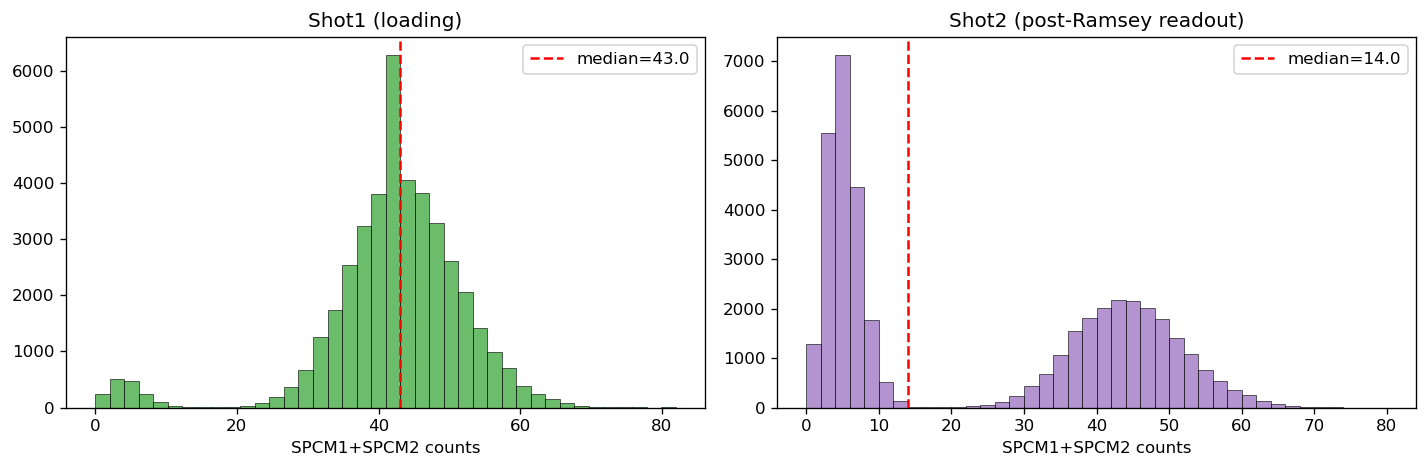

Shot1 median=43.0   Shot2 median=14.0


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(shot1_total, bins=40, color="C2", alpha=0.7, edgecolor="black", lw=0.5)
ax[0].axvline(np.median(shot1_total), color="red", ls="--", label=f"median={np.median(shot1_total):.1f}")
ax[0].set_title("Shot1 (loading)"); ax[0].set_xlabel("SPCM1+SPCM2 counts"); ax[0].legend()
ax[1].hist(shot2_total, bins=40, color="C4", alpha=0.7, edgecolor="black", lw=0.5)
ax[1].axvline(np.median(shot2_total), color="red", ls="--", label=f"median={np.median(shot2_total):.1f}")
ax[1].set_title("Shot2 (post-Ramsey readout)"); ax[1].set_xlabel("SPCM1+SPCM2 counts"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Shot1 median={np.median(shot1_total):.1f}   Shot2 median={np.median(shot2_total):.1f}")

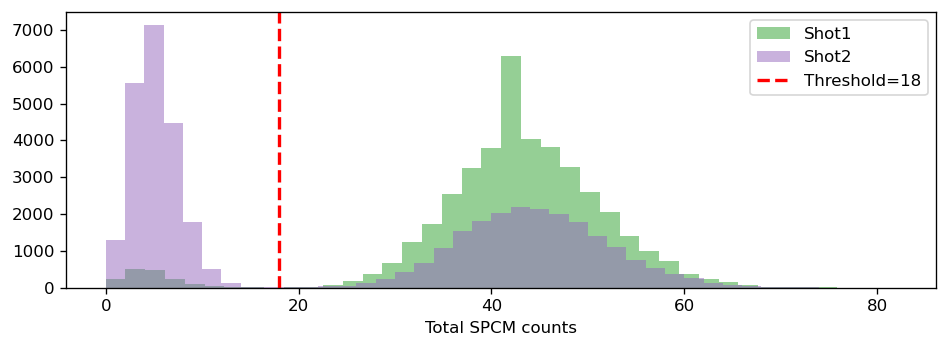

Threshold=18 | overall loading rate=96.1%


In [7]:
########################################
THRESHOLD = 18   # set from the histogram valley above
########################################
def retention_vs_freetime(field_sy, threshold):
    m = (shimY == field_sy)
    ft = free_mu[m]
    loaded = shot1_total[m] > threshold
    retained = shot2_total[m] > threshold
    uft = np.unique(ft)
    ret = np.full(len(uft), np.nan); err = np.full(len(uft), np.nan); nl = np.zeros(len(uft), int)
    for i, t in enumerate(uft):
        mm = (ft == t)
        nlo = int(loaded[mm].sum()); nret = int((loaded[mm] & retained[mm]).sum())
        nl[i] = nlo
        if nlo > 0:
            ret[i] = nret / nlo
            err[i] = np.sqrt(max(ret[i] * (1 - ret[i]), 0.0) / nlo)
    return uft / 1e6, ret, err, nl    # ft converted mu -> ms

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(shot1_total, bins=40, color="C2", alpha=0.5, label="Shot1")
ax.hist(shot2_total, bins=40, color="C4", alpha=0.5, label="Shot2")
ax.axvline(THRESHOLD, color="red", lw=2, ls="--", label=f"Threshold={THRESHOLD}")
ax.set_xlabel("Total SPCM counts"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Threshold={THRESHOLD} | overall loading rate={100 * (shot1_total > THRESHOLD).mean():.1f}%")

## 5. Global-optimizer Ramsey fit per B-field
`differential_evolution` (global) -> `curve_fit` (covariance). Errors are `sqrt(diag(pcov))`.

   Y-shim          freq(kHz)            T2*(ms)     n    vis     R2  flags
----------------------------------------------------------------------------------
   2.7200     4.653+/-0.001        14.7+/-1.1      1.46  0.771  0.865
   3.1500     3.459+/-0.001        11.9+/-0.9      1.35  0.870  0.882
   3.5900     2.773+/-0.001        13.4+/-0.7      1.83  0.899  0.886
   4.0200     2.231+/-0.001        15.1+/-0.8      1.88  0.837  0.891
   4.8800     1.446+/-0.001        12.5+/-0.8      1.60  0.844  0.869
   5.3100     1.361+/-0.001        13.6+/-0.9      1.68  0.811  0.864
   5.7500     1.159+/-0.001        15.1+/-0.8      1.57  0.881  0.886
   7.0400     0.899+/-0.001        13.4+/-1.0      1.22  0.872  0.896


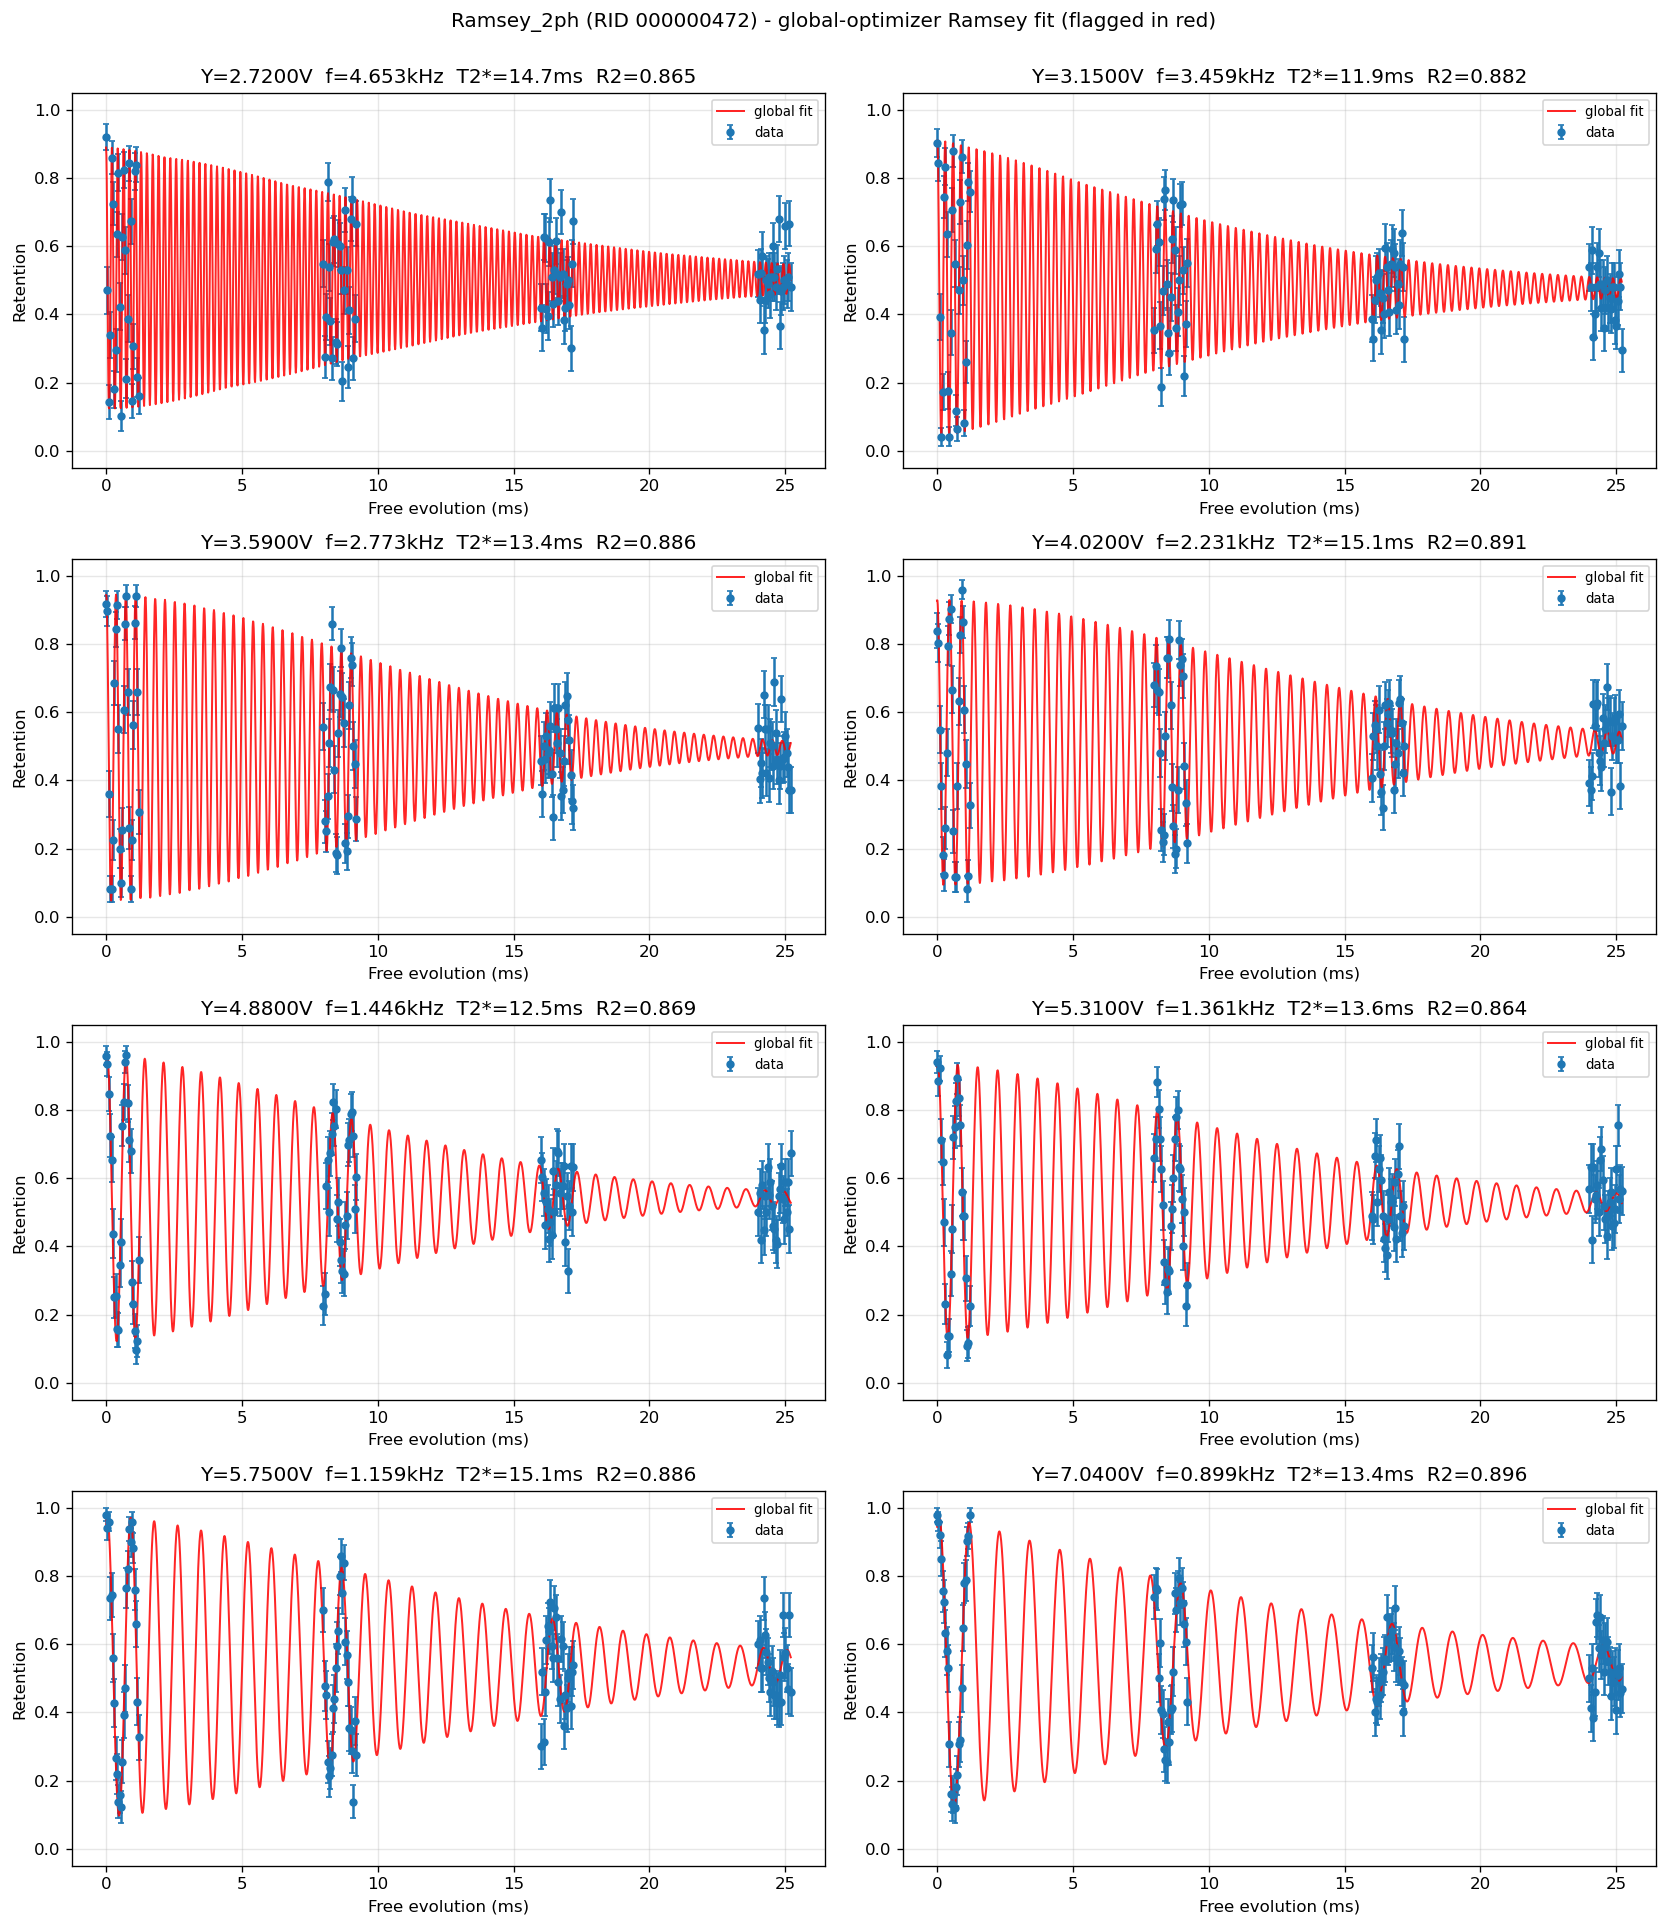

In [8]:
fit_results = {}   # field_sy -> dict(popt, perr, r2, flags)
nF = len(fields); ncols = min(nF, 2); nrows = (nF + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 4 * nrows), squeeze=False)

print(f"{'Y-shim':>9s} {'freq(kHz)':>18s} {'T2*(ms)':>18s} {'n':>5s} {'vis':>6s} {'R2':>6s}  flags")
print("-" * 82)
for k, sy in enumerate(fields):
    ax = axes[k // ncols][k % ncols]
    x_ms, ret, err, nl = retention_vs_freetime(sy, THRESHOLD)
    valid = ~np.isnan(ret)
    ax.errorbar(x_ms[valid], ret[valid], yerr=err[valid], fmt="o", color="C0", ms=4, capsize=2, label="data")
    popt = perr = None; r2 = float("nan"); flags = ["n<6 points"]
    if valid.sum() >= 6:
        popt, perr, r2, flags = fit_ramsey_global(x_ms[valid], ret[valid], err[valid])
        xfine = np.linspace(x_ms[valid].min(), x_ms[valid].max(), 2000)
        ax.plot(xfine, ramsey_model(xfine, *popt), "r-", lw=1.2, alpha=0.85, label="global fit")
        f_k, f_e = popt[1], perr[1]; t2, t2e = popt[3], perr[3]
        vis = 2 * popt[0]; nexp = popt[5]
        fstr = ("  [" + "; ".join(flags) + "]") if flags else ""
        print(f"{sy:>9.4f} {f_k:>9.3f}+/-{f_e:<7.3f} {t2:>9.1f}+/-{t2e:<7.1f} {nexp:>5.2f} {vis:>6.3f} {r2:>6.3f}{fstr}")
        ttl = f"Y={sy:.4f}V  f={f_k:.3f}kHz  T2*={t2:.1f}ms  R2={r2:.3f}"
        ax.set_title(ttl + ("  [!]" if flags else ""), color=("red" if flags else "black"))
    else:
        print(f"{sy:>9.4f}  too few points ({int(valid.sum())})")
        ax.set_title(f"Y={sy:.4f}V (n<6)", color="red")
    fit_results[sy] = dict(popt=popt, perr=perr, r2=r2, flags=flags)
    ax.set_xlabel("Free evolution (ms)"); ax.set_ylabel("Retention")
    ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=8)
for j in range(nF, nrows * ncols):
    axes[j // ncols][j % ncols].axis("off")
plt.suptitle(f"{mode} (RID {run_rid}) - global-optimizer Ramsey fit (flagged in red)", y=1.0)
plt.tight_layout(); plt.show()

## 6. Segment zoom per B-field
The 4 free-evolution windows (~0/8/16/24 ms) per field, with the global fit overlaid.

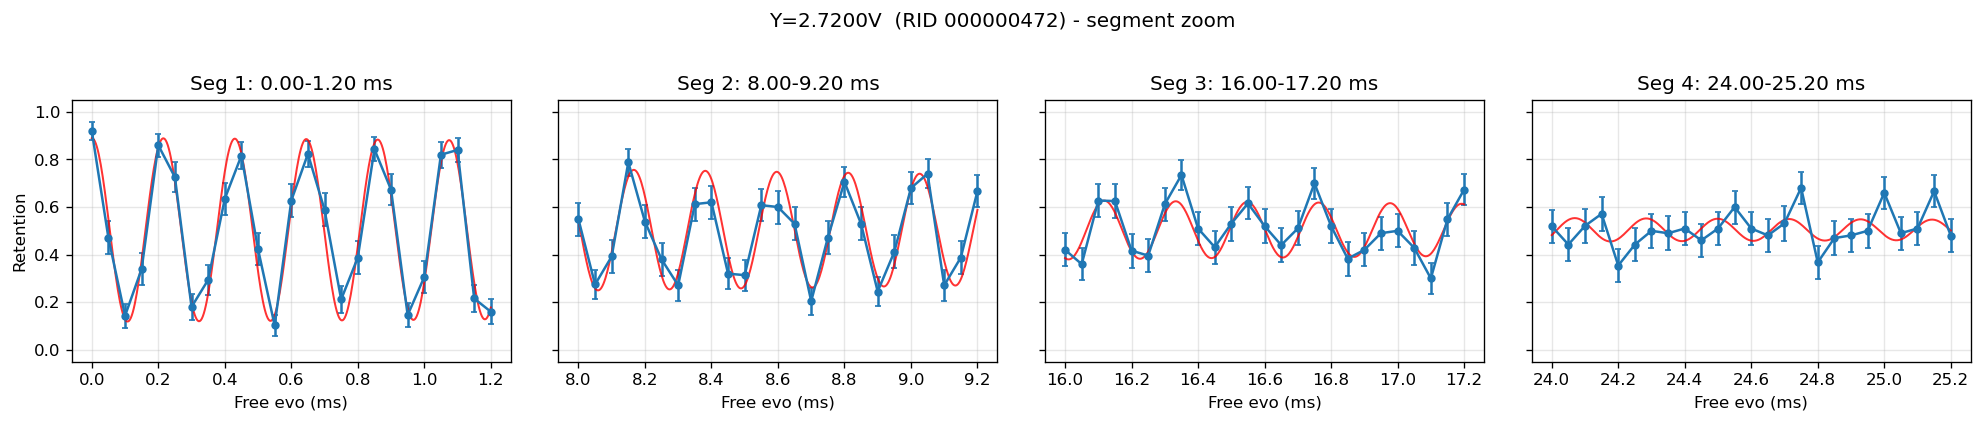

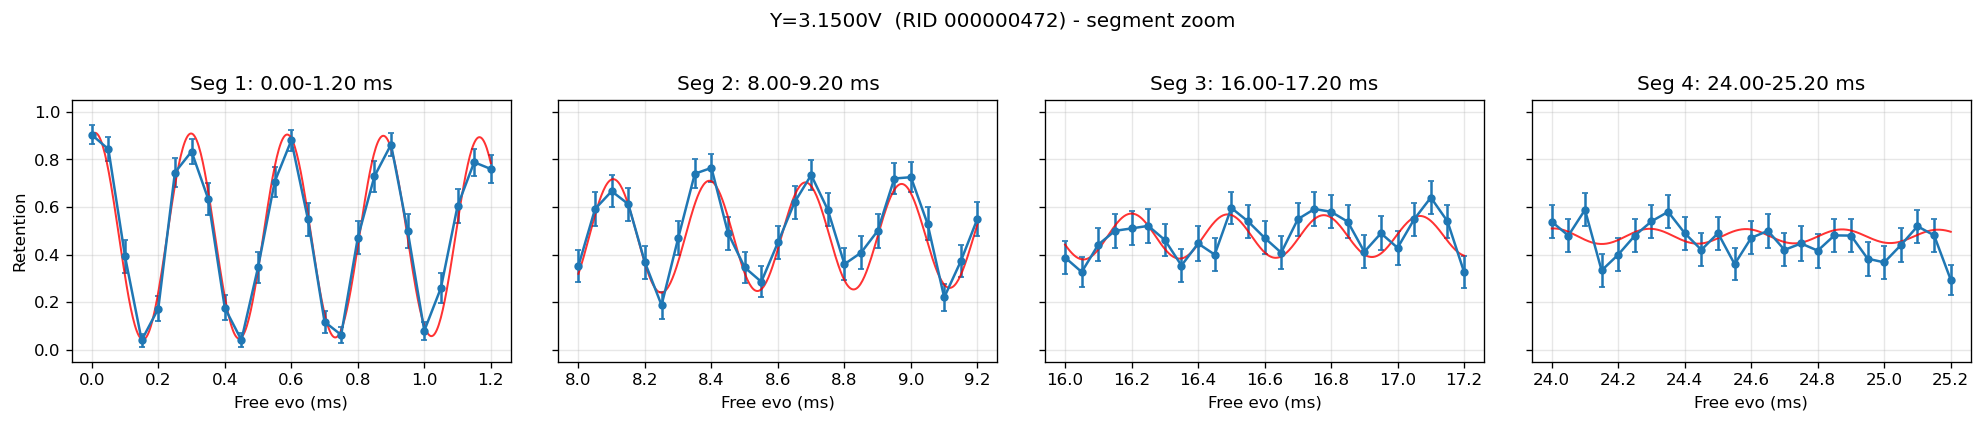

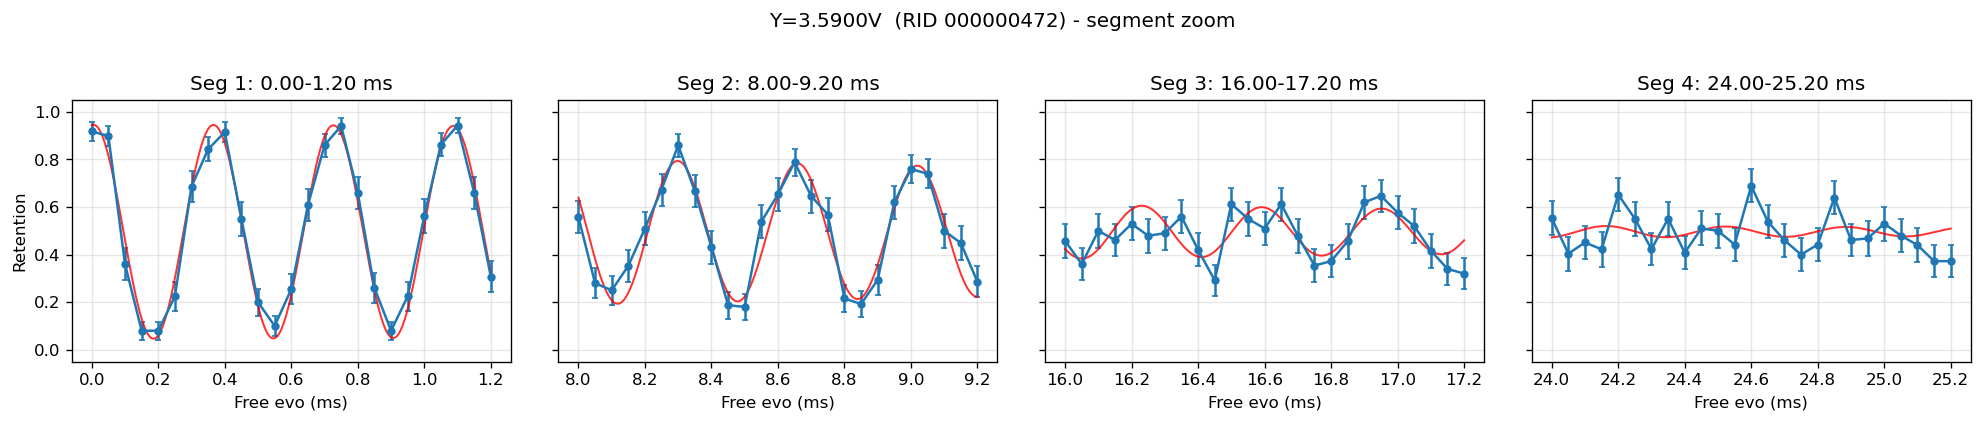

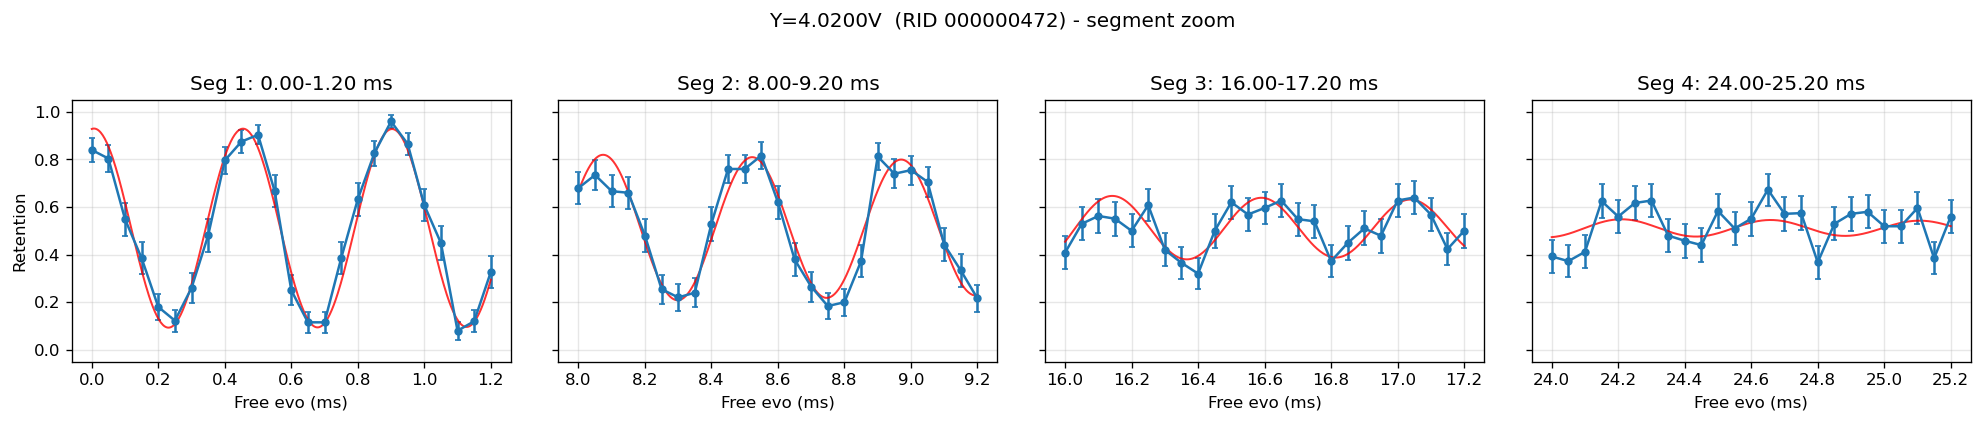

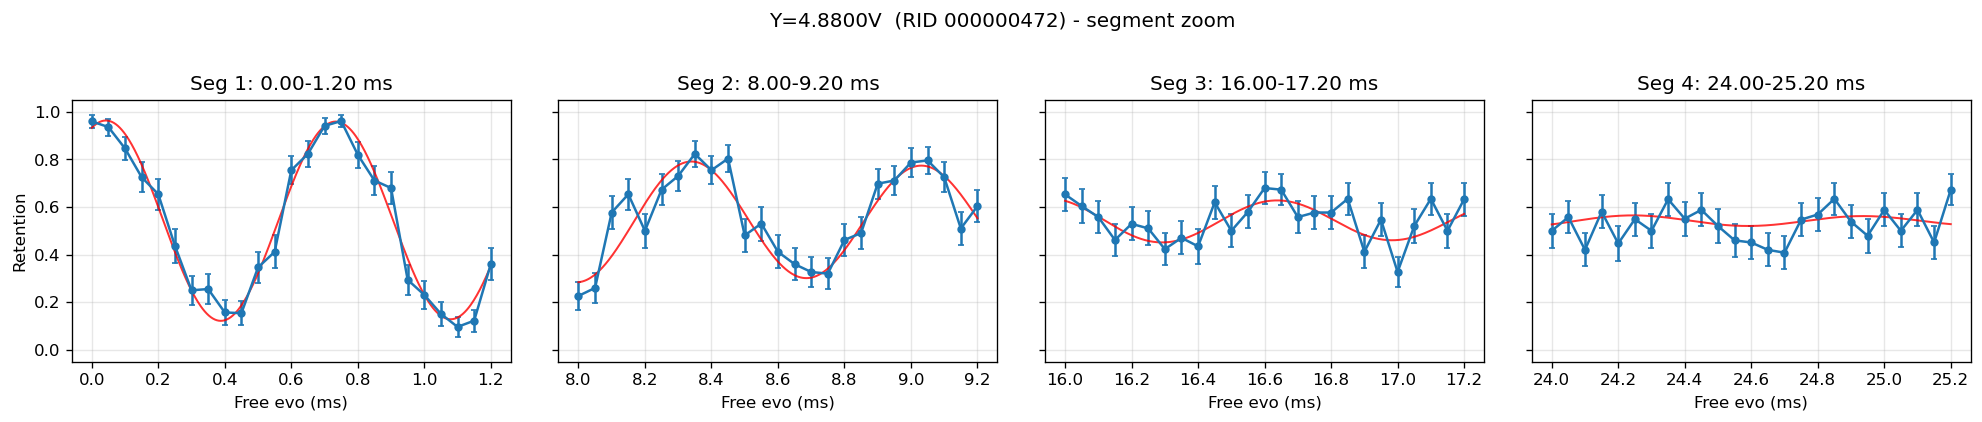

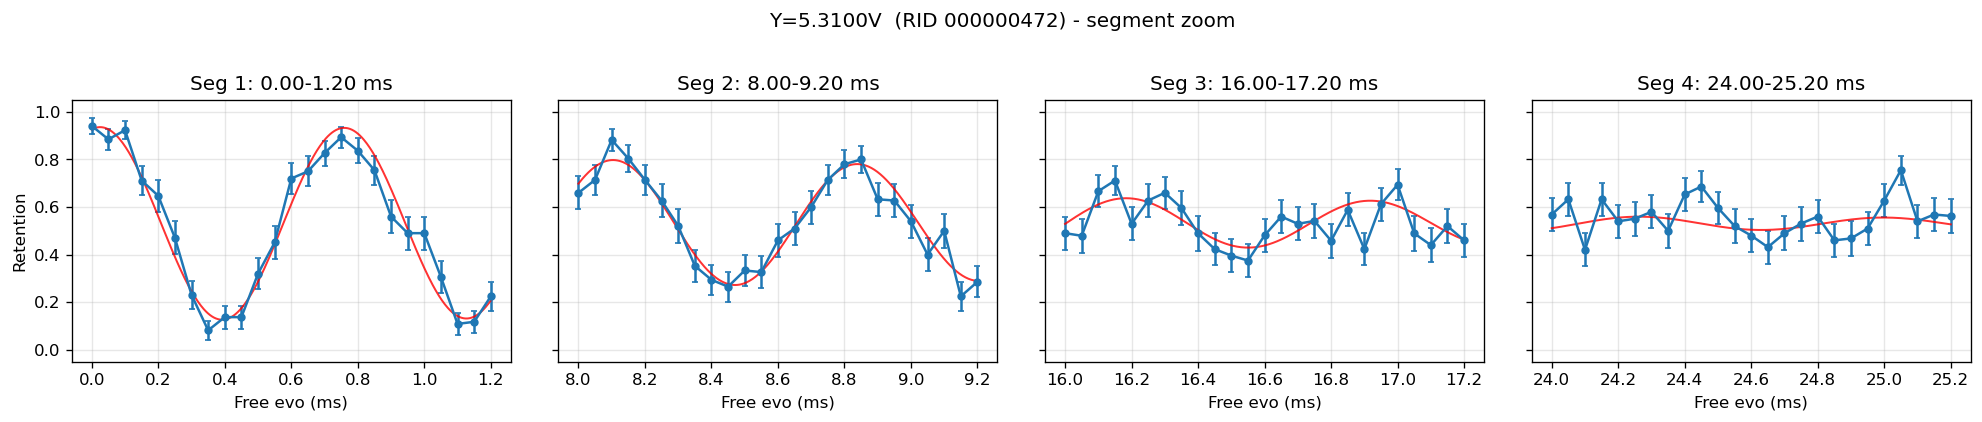

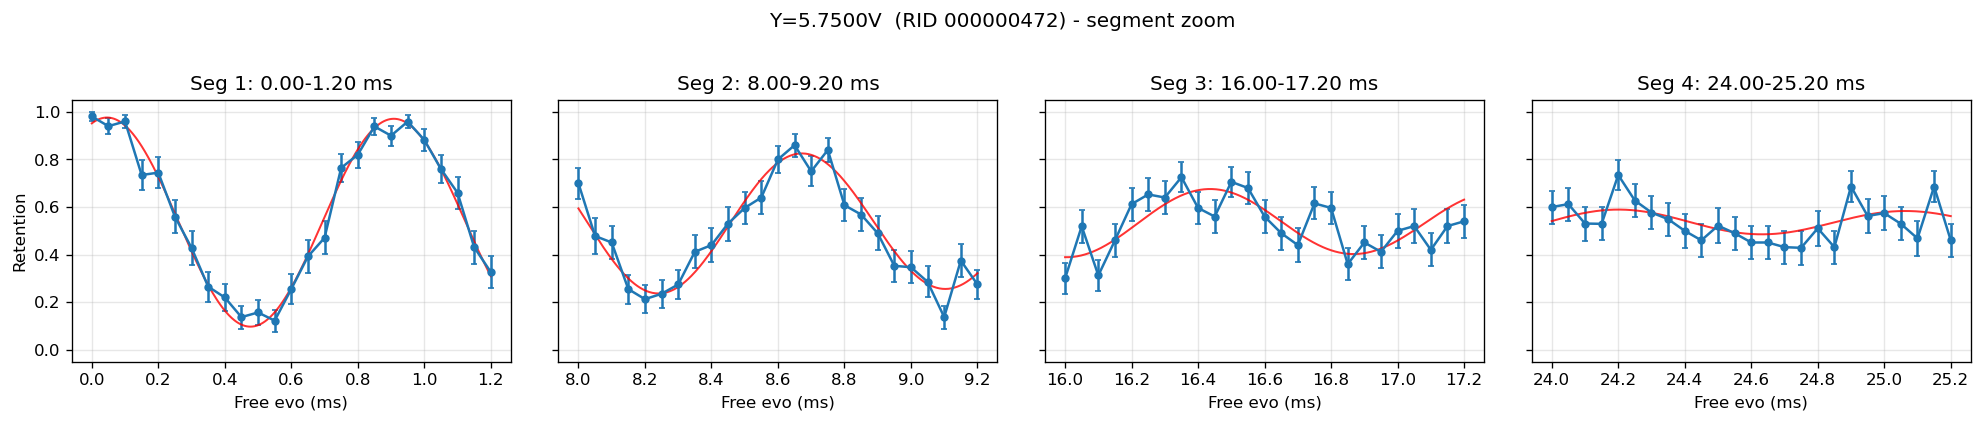

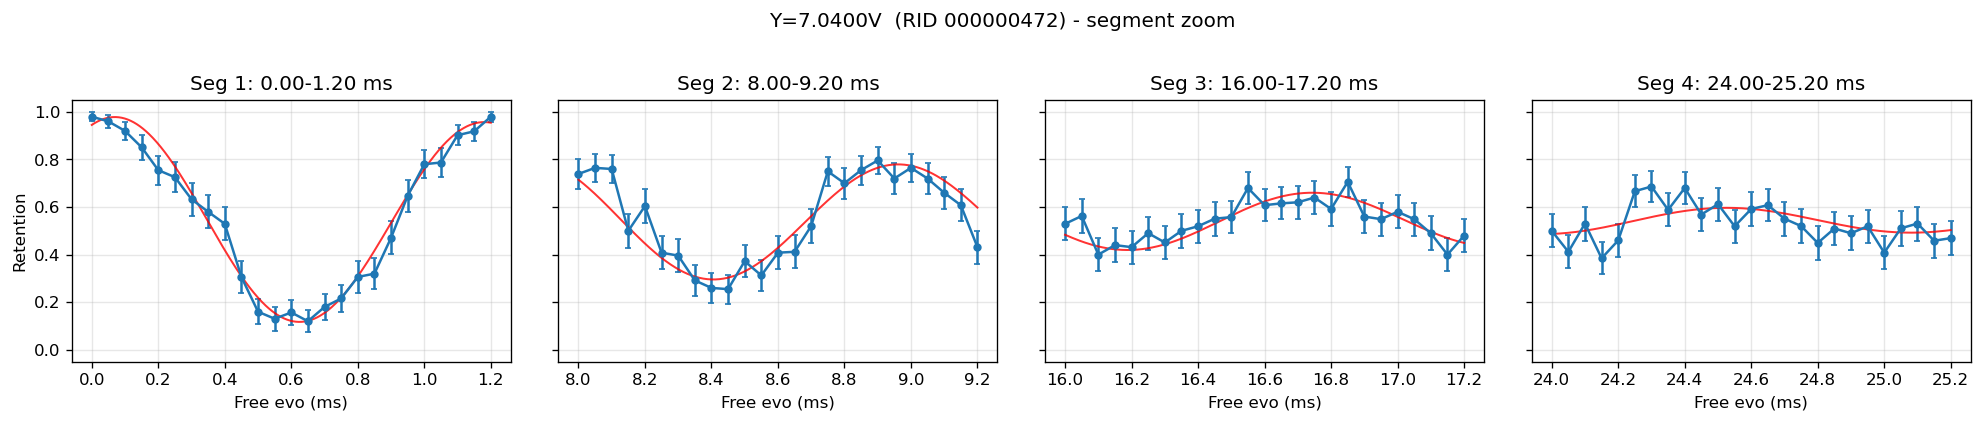

In [9]:
for sy in fields:
    x_ms, ret, err, nl = retention_vs_freetime(sy, THRESHOLD)
    valid = ~np.isnan(ret)
    xv, rv, ev = x_ms[valid], ret[valid], err[valid]
    if len(xv) < 2:
        print(f"Y={sy:.4f}V: too few points for segment zoom"); continue
    diffs = np.diff(xv); med = np.median(diffs)
    gaps = np.where(diffs > 2 * med)[0]
    starts = np.concatenate([[0], gaps + 1]); ends = np.concatenate([gaps + 1, [len(xv)]])
    nseg = len(starts)
    popt = fit_results.get(sy, {}).get("popt")
    fig, axs = plt.subplots(1, nseg, figsize=(4.2 * nseg, 3.4), sharey=True, squeeze=False)
    axs = axs[0]
    for s, (si, ei) in enumerate(zip(starts, ends)):
        xs, rs, es = xv[si:ei], rv[si:ei], ev[si:ei]
        axs[s].errorbar(xs, rs, yerr=es, fmt="o-", color="C0", ms=4, capsize=2)
        if popt is not None and len(xs) > 1:
            xf = np.linspace(xs[0], xs[-1], 400)
            axs[s].plot(xf, ramsey_model(xf, *popt), "r-", lw=1.2, alpha=0.8)
        axs[s].set_ylim(-0.05, 1.05); axs[s].grid(alpha=0.3)
        axs[s].set_title(f"Seg {s+1}: {xs[0]:.2f}-{xs[-1]:.2f} ms"); axs[s].set_xlabel("Free evo (ms)")
    axs[0].set_ylabel("Retention")
    plt.suptitle(f"Y={sy:.4f}V  (RID {run_rid}) - segment zoom", y=1.02)
    plt.tight_layout(); plt.show()

## 7. Coherence vs B-field
Fitted T2* and fringe frequency vs Y-shim, with pcov error bars.

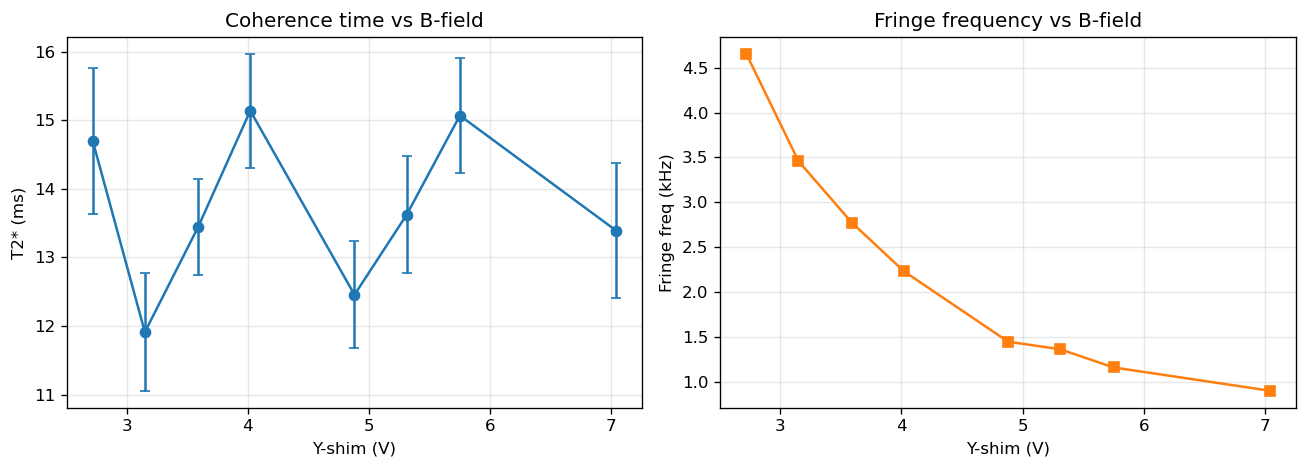

In [10]:
ys, fs, fse, taus, tause = [], [], [], [], []
for sy in fields:
    fr = fit_results.get(sy, {})
    popt, perr = fr.get("popt"), fr.get("perr")
    if popt is not None:
        ys.append(sy); fs.append(popt[1]); fse.append(perr[1]); taus.append(popt[3]); tause.append(perr[3])
if ys:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].errorbar(ys, taus, yerr=tause, fmt="o-", color="C0", capsize=3)
    ax[0].set_xlabel("Y-shim (V)"); ax[0].set_ylabel("T2* (ms)")
    ax[0].set_title("Coherence time vs B-field"); ax[0].grid(alpha=0.3)
    ax[1].errorbar(ys, fs, yerr=fse, fmt="s-", color="C1", capsize=3)
    ax[1].set_xlabel("Y-shim (V)"); ax[1].set_ylabel("Fringe freq (kHz)")
    ax[1].set_title("Fringe frequency vs B-field"); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("No successful fits to summarize.")

## 8. Browse datasets

In [203]:
print("=== datasets/ ===")
for k in sorted(data.keys()):
    v = data[k]
    if isinstance(v, np.ndarray) and v.size > 0:
        print(f"  {k:32s} {str(v.dtype):8s} shape={str(v.shape):12s} [{v.min():.4g} .. {v.max():.4g}]")
    elif isinstance(v, np.ndarray):
        print(f"  {k:32s} {str(v.dtype):8s} (empty)")
    else:
        print(f"  {k:32s} = {_txt(v)}")

=== datasets/ ===
  rqs_atom_loaded                  int32    shape=(25600,)     [0 .. 1]
  rqs_atom_retained                int32    shape=(25600,)     [0 .. 1]
  rqs_bg_spcm1                     int32    shape=(25600,)     [0 .. 17]
  rqs_bg_spcm2                     int32    shape=(25600,)     [0 .. 15]
  rqs_f01_hz                       float64  shape=(25600,)     [2.505e+08 .. 2.515e+08]
  rqs_field_f01_hz                 float64  shape=(8,)         [2.505e+08 .. 2.515e+08]
  rqs_field_fm10_2ph_hz            float64  shape=(8,)         [2.483e+08 .. 2.494e+08]
  rqs_field_order                  int32    shape=(8,)         [0 .. 7]
  rqs_field_rf_2ph_ramsey_hz       float64  shape=(8,)         [6.019e+05 .. 1.657e+06]
  rqs_field_shimX                  float64  shape=(8,)         [-0.013 .. -0.013]
  rqs_field_shimY                  float64  shape=(8,)         [2.72 .. 7.04]
  rqs_field_shimZ1                 float64  shape=(8,)         [-0.06 .. -0.06]
  rqs_field_shimZ2          